# 性能分析（DICHASUS）

In [2]:
import itertools
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
os.environ['TF_ENABLE_ONEDNN_OPTS'] = '0'

import glob
from typing import Optional

import h5py
import pandas as pd
import numpy as np
from matplotlib import rcParams
import matplotlib.pyplot as plt
import matplotlib.colors as colors
import matplotlib.ticker as ticker

# ================= 配置区域 =================
EXP_DIR = './exp/DICHASUS/0152-0157_DirectSample512to32'
TEST_FOLDER = "test"
TEST_DATASET = "0152-0157_DirectSample512to32_v2"

INPUT_CONFIG_LABELS = {
    # '6antx6car': r'6 antennas $\times$ 6 carriers',
    '8antx8car': r'8 antennas $\times$ 8 carriers',
    # '10antx10car': r'10 antennas $\times$ 10 carriers',
    '12antx12car': r'12 antennas $\times$ 12 carriers',
    '16antx16car': r'16 antennas $\times$ 16 carriers',
}

TRAIN_DATA_CONFIG_LABELS = {
    'data36k-nei32': '36,000 training data',
}

#TODO: 还没测 AFCoupler 的 dropout
MODEL_DIR_NAMES = {
    'ConvCoupler': 'ConvCoupler-d256-dropout',
    'ACoupler': 'ACoupler-d256-dropout_noAgghead1',
    'AFCoupler': 'AFCoupler-d256-dropout',
    'RCDNet': 'RCDNet-d512-dropout',
    'ACDNet': 'ACDNet-d512-dropout',
    # 'AFCDNet': 'AFCDNet_ckpt5w',
    'ConvLSTM': 'ConvLSTM-depth2-ch16',
    'LMMSE': 'LMMSE'
}

# 输出保存目录（包括图片和csv）
SAVE_DIR = "./results/DICHASUS-015x"

# ================= 绘图样式设置 (复刻旧代码风格) =================
plot_config = {
    "font.family": 'Times New Roman',
    "font.size": 14,
    # === 1. 强制显示边框 (之前解决的问题) ===
    "axes.spines.top": True,
    "axes.spines.right": True,
    "axes.spines.bottom": True,
    "axes.spines.left": True,

    # === 2. 刻度线设置 (核心修改) ===
    "xtick.direction": "in",      # 刻度线朝内
    "ytick.direction": "in",      # 刻度线朝内
    "xtick.major.size": 6,        # 主刻度长度
    "ytick.major.size": 6,
    "xtick.minor.size": 3,        # 次刻度长度 (更短)
    "ytick.minor.size": 3,
    "xtick.minor.visible": True,  # 强制显示次刻度
    "ytick.minor.visible": True,

    "xtick.bottom": True,            # 下边框显示刻度
    "xtick.top": False,            #
    "ytick.left": True,          # 左边框显示刻度
    "ytick.right": False,          #
    # "axes.labelsize": 16,
    # "xtick.labelsize": 14,
    # "ytick.labelsize": 14,
    # "legend.fontsize": 14,
    # "lines.linewidth": 2,
    # "axes.grid": True,
    # "grid.alpha": 0.5,
    # "grid.linestyle": '--'
}
rcParams.update(plot_config)

# 定义颜色 (复刻 Set1)
# COLORS = ['#e41a1c', '#377eb8', '#4daf4a', '#984ea3', '#ff7f00']
LINESTYLES = ['-', '--']
MARKERS = ['o', '^', 's', 'd', 'v', 'x']
palette1 = plt.get_cmap('Set1')
palette2 = plt.get_cmap('Pastel1')
linecolors = [palette1(1), palette1(2), palette1(4), palette1(6), palette1(3), palette1(8)]
facecolors = [palette2(1), palette2(2), palette2(4), palette2(5)]


#TODO: 后续将 train_data_config 改为必选参数
def load_csv(input_config, model_dir_name, task,
             train_data_config: Optional[str]=None):
    """ 辅助函数：返回 csv 读取 """
    if train_data_config is None:
        path = os.path.join(EXP_DIR, f'input_{input_config}', model_dir_name, 'test',
                            TEST_DATASET, 'test', f'{task}.csv')
    else:
        assert isinstance(train_data_config, str)
        path = os.path.join(EXP_DIR, f'input_{input_config}', train_data_config,
                            model_dir_name, 'test', TEST_DATASET, 'test', f'{task}.csv')

    if not os.path.exists(path):
        print(f"⚠️ Warning: File not found: {path}")
        return None
    else:
        return pd.read_csv(path)


def load_and_align_data(input_config, model_name, trace_filename, metric_key,
                        train_data_config: Optional[str]=None):
    """
    加载数据并根据 past_len 对齐轨迹和指标
    """
    model_dir_name = MODEL_DIR_NAMES[model_name]
    if train_data_config is None:
        h5_path = os.path.join(EXP_DIR, f'input_{input_config}',
                               model_dir_name, TEST_FOLDER, TEST_DATASET,
                               'trace_smooth', trace_filename)
    else:
        assert isinstance(train_data_config, str)
        h5_path = os.path.join(EXP_DIR, f'input_{input_config}', train_data_config,
                               model_dir_name, TEST_FOLDER, TEST_DATASET,
                               'trace_smooth', trace_filename)

    if not os.path.exists(h5_path):
        raise FileNotFoundError(f"文件未找到: {h5_path}")

    with h5py.File(h5_path, 'r') as f:
        # 读取元数据
        past_len = f.attrs['past_len']
        part_name = f.attrs.get('part_name', 'Unknown Part')
        print(f"[Info] Loading {part_name}, Past Length: {past_len}")

        # 3. 读取数据
        loc_full = f['loc'][:]    # loc shape: [Total_Len, 3] (x, y, z)
        metric_data = f[metric_key][:]    # metric shape: [Total_Len - Past_Len]

        # 4. 对齐数据
        # 这里的逻辑是：metric[0] 对应的是 loc[past_len] 时刻的预测结果
        # 因为前 past_len 个时刻是用来做 warm-up 的，没有预测输出
        assert len(metric_data) == len(loc_full) - past_len
        loc_aligned = loc_full[past_len:]

    return loc_aligned, metric_data, past_len, part_name


def save_plot(filename):
    """ 保存为 pdf, jpg, eps """
    os.makedirs(SAVE_DIR, exist_ok=True)
    base = os.path.join(SAVE_DIR, filename)
    plt.savefig(f"{base}.pdf", bbox_inches='tight')
    plt.savefig(f"{base}.jpg", bbox_inches='tight', dpi=300)
    # plt.savefig(f"{base}.eps", bbox_inches='tight') # 需要时取消注释
    print(f"✅ Saved: {base}.pdf/jpg")


def save_csv(df, filename):
    """ 保存为 pdf, jpg, eps """
    if not filename.endswith('.csv'):
        filename += '.csv'
    os.makedirs(SAVE_DIR, exist_ok=True)
    base = os.path.join(SAVE_DIR, filename)
    df.to_csv(base, index=False)
    print(f"✅ Saved: {base}")


## 历史长度影响曲线

Plotting History Length Impact...


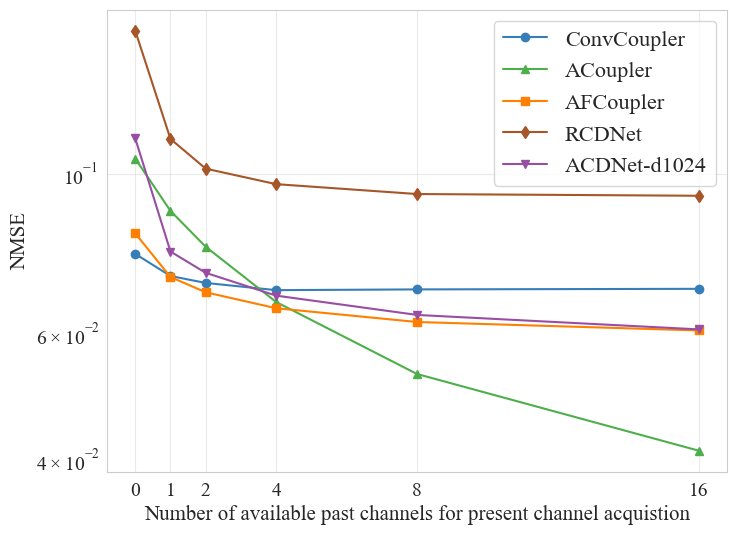

In [28]:
def plot_history_length(
        input_config: str, train_data_config: str,
        active_model_names: Optional[list[str]] = None,
        fig_name: str = "NMSE_pastlen",
        is_save: bool = True):
    """ 5. 绘制历史长度影响曲线 """
    print("Plotting History Length Impact...")
    plt.figure(figsize=(8, 6))
    plt.yscale('log')

    for i, (model_name, model_dir_name) in enumerate(MODEL_DIR_NAMES.items()):
        if active_model_names is not None and model_name not in active_model_names:
            continue

        df = load_csv(input_config, model_dir_name, 'history_len',
                      train_data_config=train_data_config)

        grouped = df.groupby('past_len')['nmse'].mean().sort_index()
        x = grouped.index
        y = grouped.values
        label = f'{model_name}'
        plt.plot(x, y, label=label,
                 marker=MARKERS[i % len(MARKERS)],
                 linestyle=LINESTYLES[0],
                 color=linecolors[i])

    plt.ylabel("NMSE", fontsize=15)
    plt.xlabel("Number of available past channels for present channel acquistion", fontsize=15)
    plt.xticks([0, 1, 2, 4, 8, 16])
    plt.grid(alpha=0.4)
    plt.legend(prop={'size': 16}, ncol=1)
    if is_save:
        save_plot(f"{fig_name}")
    plt.show()
    plt.close()


input_config = '8antx8car'
train_data_config = 'data36k-nei32'
fig_name = 'data36k-nei32_NMSE_pastlen'
plot_history_length(input_config, train_data_config,
                    fig_name=fig_name,
                    is_save=False)

## 噪声鲁棒性曲线（实测数据本来就有噪，测这个意义不大）

Plotting Noise Robustness (Add Noise to: past)...


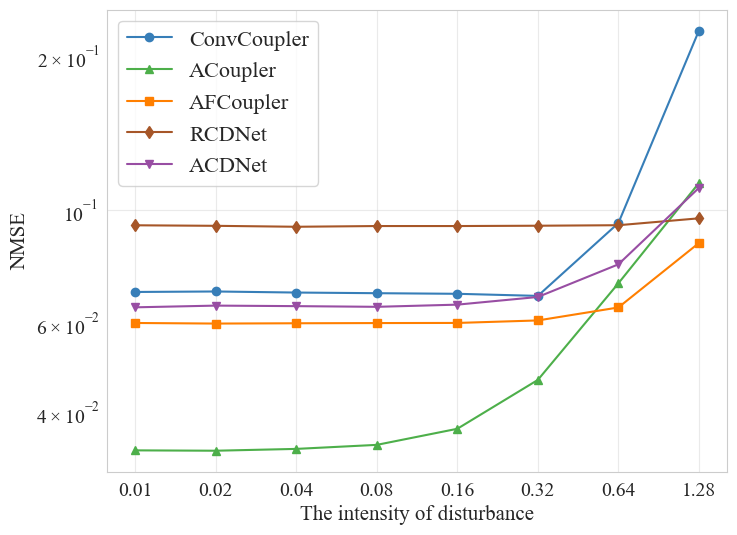

Plotting Noise Robustness (Add Noise to: all)...


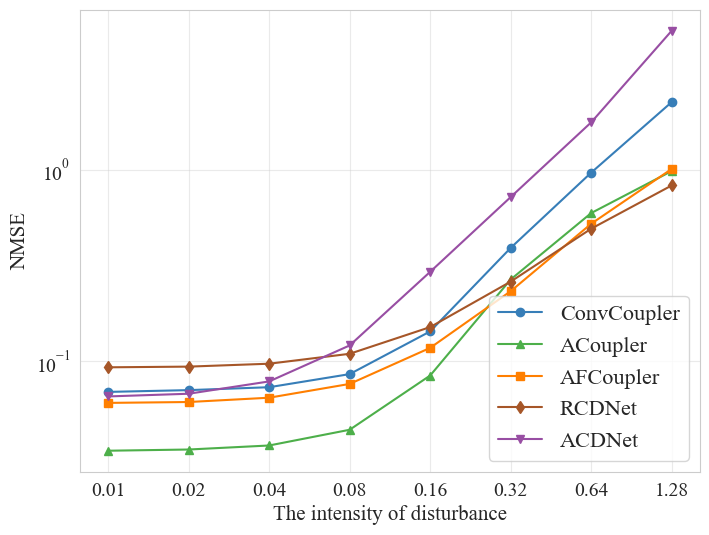

In [20]:
def plot_noise_robustness(
        input_config: str, train_data_config: str,
        noise_target: str = 'all',
        legend_loc: str = 'upper left',
        fig_name: str = "NMSE_noise_disturb",
        is_save: bool = True):
    """ 绘制噪声鲁棒性曲线 (target='all' or 'past') """
    print(f"Plotting Noise Robustness (Add Noise to: {noise_target})...")
    plt.figure(figsize=(8, 6))
    plt.yscale('log')
    plt.xscale('log')

    for i, (model_name, model_dir_name) in enumerate(MODEL_DIR_NAMES.items()):
        df = load_csv(input_config, model_dir_name, 'production_noise',
                      train_data_config=train_data_config)
        sub_df = df[df['noise_target'] == noise_target]
        grouped = sub_df.groupby('noise_level')['nmse'].mean().sort_index()
        x = grouped.index
        y = grouped.values
        label = f'{model_name}'
        plt.plot(x[1:], y[1:], label=label,
                 marker=MARKERS[i % len(MARKERS)],
                 linestyle=LINESTYLES[0],
                 color=linecolors[i])


    plt.ylabel("NMSE", fontsize=15)
    plt.xlabel("The intensity of disturbance", fontsize=15)
    # plt.ylim(0.001, 2)
    plt.xticks([0.01, 0.02, 0.04, 0.08, 0.16, 0.32, 0.64, 1.28],
               [0.01, 0.02, 0.04, 0.08, 0.16, 0.32, 0.64, 1.28])
    # plt.xlim(0.008, 1.5)
    plt.grid(alpha=0.4)
    plt.legend(fontsize=16, loc=legend_loc)
    if is_save:
        save_plot(f"{fig_name}_{noise_target}")
    plt.show()
    plt.close()


input_config = '8antx8car'
train_data_config = 'data36k-nei32'
fig_name = 'data36k-nei32_NMSE_noise_disturb'
plot_noise_robustness(input_config, train_data_config,
                      noise_target='past',
                      legend_loc='upper left',
                      fig_name=fig_name, is_save=False)
plot_noise_robustness(input_config, train_data_config,
                      noise_target='all',
                      legend_loc='lower right',
                      fig_name=fig_name, is_save=False)

## 不同输入维度、不同模型的性能箱线图

Plotting NMSE Schemes Boxplot (Past Len: 16, Show Outliers: False)...
✅ Saved: ./results/DICHASUS-015x/NMSE_boxplot_schemes_len16.pdf/jpg


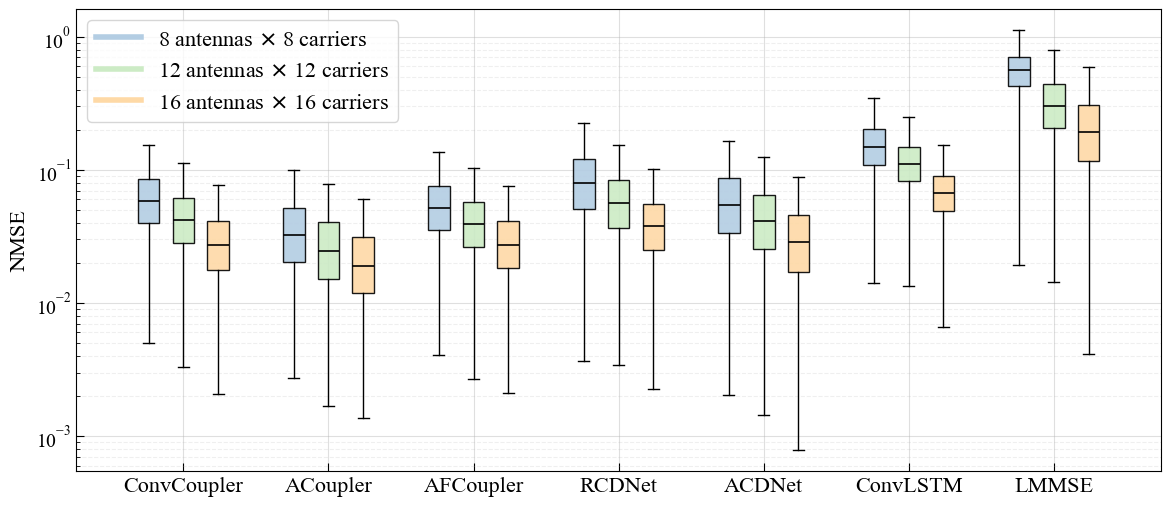


NMSE Statistics Summary (Past Len: 16)
                  Input_Config_Label        Model  Past_Len     Mean  Median (50%)  Q1 (25%)  Q3 (75%)      Min      Max      Std  Count
0     8 antennas $\times$ 8 carriers  ConvCoupler        16 6.92e-02      5.86e-02  3.99e-02  8.55e-02 4.97e-03 8.12e-01 4.63e-02  36000
1     8 antennas $\times$ 8 carriers     ACoupler        16 4.12e-02      3.24e-02  2.03e-02  5.21e-02 2.71e-03 6.68e-01 3.18e-02  36000
2     8 antennas $\times$ 8 carriers    AFCoupler        16 6.05e-02      5.17e-02  3.53e-02  7.57e-02 4.08e-03 6.06e-01 3.86e-02  36000
3     8 antennas $\times$ 8 carriers       RCDNet        16 9.32e-02      7.93e-02  5.04e-02  1.20e-01 3.68e-03 1.88e+00 6.27e-02  36000
4     8 antennas $\times$ 8 carriers       ACDNet        16 6.72e-02      5.49e-02  3.36e-02  8.65e-02 2.04e-03 1.66e+00 5.07e-02  36000
5     8 antennas $\times$ 8 carriers     ConvLSTM        16 1.64e-01      1.48e-01  1.08e-01  2.03e-01 1.42e-02 3.26e+00 8.82e-02  36000
6

In [3]:
def plot_nmse_schemes_boxplot(
        input_configs: list[str], train_data_config: str,
        past_len: int,
        show_outliers: bool = False,
        fig_name: str = "NMSE_boxplot_schemes",
        is_save: bool = True):
    """
    绘制不同 Schemes 在特定 past_len 下的 NMSE 分组箱线图
    """
    # mode_str = "Mixed Scenarios" if is_mix else "Separate Scenarios"
    print(f"Plotting NMSE Schemes Boxplot (Past Len: {past_len}, Show Outliers: {show_outliers})...")

    model_names = list(MODEL_DIR_NAMES.keys())
    stats_results = []  # <--- [新增] 用于存储统计结果

    # --- 1. 确定 X 轴的分类 (Schemes) ---
    # if is_mix:
    # 混合模式：X 轴仅为模型名
    scheme_keys = model_names
    scheme_labels = [model_name for model_name in model_names]
    # else:
    #     # 分离模式：X 轴为模型+场景
    #     scheme_keys = list(itertools.product(model_names, scenarios))
    #     scheme_labels = [f'{m}\n({SCENARIO_NAMES[s]})' for (m, s) in scheme_keys]

    # --- 2. 准备绘图坐标 ---
    x = np.arange(len(scheme_keys))
    width = 0.15  # 箱子的宽度
    dw = 1.6 * width  # 组间间距因子
    dw_list = (np.arange(len(input_configs)) - (len(input_configs) - 1) / 2) * dw

    plt.figure(figsize=(14, 6))
    plt.yscale('log')

    # --- 3. 遍历每个配置 (Input Config) 进行数据收集与绘图 ---
    for i, input_config in enumerate(input_configs):
        data_for_config = []  # 存储当前 input_config 下，所有 X 轴位置的数据
        input_config_label = INPUT_CONFIG_LABELS[input_config]

        # 遍历 X 轴的每一个位置 (Scheme)
        for key in scheme_keys:
            model_name = key   # key 是 model_name
            model_dir = MODEL_DIR_NAMES[model_name]

            # 加载 'history_len' 类型的文件，并筛选特定的 past_len
            df = load_csv(input_config, model_dir, 'history_len',
                          train_data_config=train_data_config)
            df_filtered = df[df['past_len'] == past_len]
            current_data = df_filtered['nmse'].values
            data_for_config.append(current_data)

            stats_results.append({
                'Input_Config': input_config,
                'Input_Config_Label': input_config_label,
                'Model': model_name,
                'Past_Len': past_len,
                'Count': len(current_data),
                'Mean': np.mean(current_data),
                'Std': np.std(current_data),
                'Min': np.min(current_data),
                'Q1 (25%)': np.percentile(current_data, 25),
                'Median (50%)': np.median(current_data),
                'Q3 (75%)': np.percentile(current_data, 75),
                'Max': np.max(current_data)
            })

        # --- 4. 绘制箱线图 ---
        positions = x + dw_list[i]

        bp = plt.boxplot(
            data_for_config,
            positions=positions,
            widths=width,
            patch_artist=True,
            showfliers=show_outliers,
            flierprops={
                'marker': 'o', 'markerfacecolor': 'gray', 'markeredgecolor': 'none',
                'markersize': 2, 'alpha': 0.1
            },
            medianprops={'color': 'black', 'linewidth': 1.2}
        )

        # 给箱子上色
        for patch in bp['boxes']:
            patch.set_facecolor(facecolors[i]) # 假设 facecolors 是外部定义的全局变量
            patch.set_alpha(0.9)

        # 添加图例 Dummy

        plt.plot([], [], color=facecolors[i], label=input_config_label, linewidth=4)

    # --- 5. 装饰 ---
    plt.xticks(ticks=x, labels=scheme_labels, rotation=0, fontsize=16)
    plt.tick_params(axis='x', which='minor', bottom=False, top=False)   # 关闭 X 轴的次要刻度线（底部和顶部）
    plt.ylabel(f'NMSE', fontsize=16) # 更新 Y 轴标签提示 past_len
    # plt.ylim(bottom=5e-5, top=8e-1)
    plt.grid(True, alpha=0.4)
    plt.grid(True, which="major", axis='y', linestyle='-', alpha=0.4)
    plt.grid(True, which="minor", axis='y', linestyle='--', alpha=0.2)
    plt.legend(fontsize=16, loc='upper left')
    # plt.title(f"NMSE Performance at History Length = {past_len}") # 可选：加个标题

    # 更新文件名以包含 past_len
    final_fig_name = f"{fig_name}_len{past_len}"

    if is_save:
        save_plot(final_fig_name)
    plt.show()
    plt.close()

    # --- [新增] 整理并保存统计数据 ---
    if stats_results:
        csv_filename = f"{final_fig_name}_stats.csv"
        df_stats = pd.DataFrame(stats_results)

        # 调整列显示顺序
        cols = ['Input_Config_Label', 'Model', 'Past_Len',
                'Mean', 'Median (50%)', 'Q1 (25%)', 'Q3 (75%)',
                'Min', 'Max', 'Std', 'Count']
        cols = [c for c in cols if c in df_stats.columns]
        df_stats = df_stats[cols]

        print("\n" + "="*80)
        print(f"NMSE Statistics Summary (Past Len: {past_len})")
        print("="*80)
        pd.set_option('display.max_rows', None)
        pd.set_option('display.width', 1000)
        pd.set_option('display.float_format', '{:.2e}'.format) # 使用科学计数法显示
        print(df_stats)
        print("="*80 + "\n")

        if is_save:
            save_csv(df_stats, csv_filename)

# --- 运行调用示例 ---
input_configs = ['8antx8car', '12antx12car', '16antx16car']
train_data_config = 'data36k-nei32'
target_past_len = 16  # <--- 指定你要画的历史长度，例如 12

plot_nmse_schemes_boxplot(
    input_configs,
    train_data_config,
    past_len=target_past_len,  # 传入参数
    is_save=True
)


## 无误差传播 / 自回归轨迹的 NMSE 性能曲线

[Info] Loading dichasus-0158, Past Length: 0
✅ Saved: ./results/DICHASUS-015x/trace_heatmap_len0.pdf/jpg


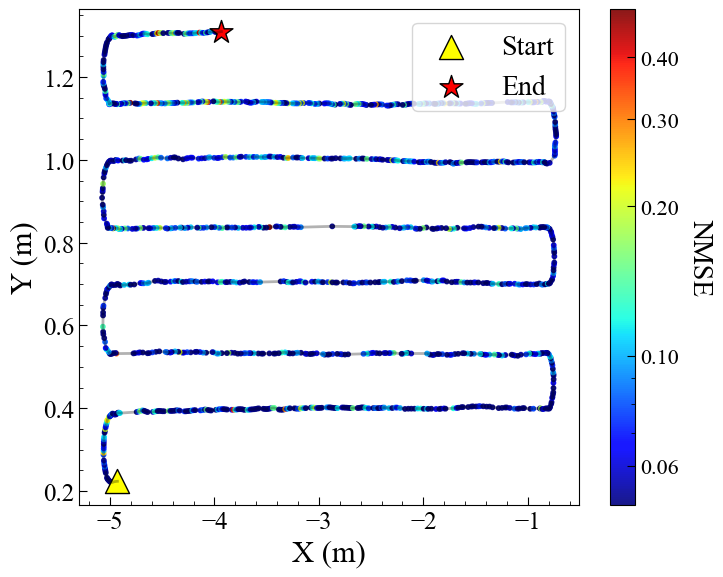

[Info] Loading dichasus-0158, Past Length: 1
✅ Saved: ./results/DICHASUS-015x/trace_heatmap_len1.pdf/jpg


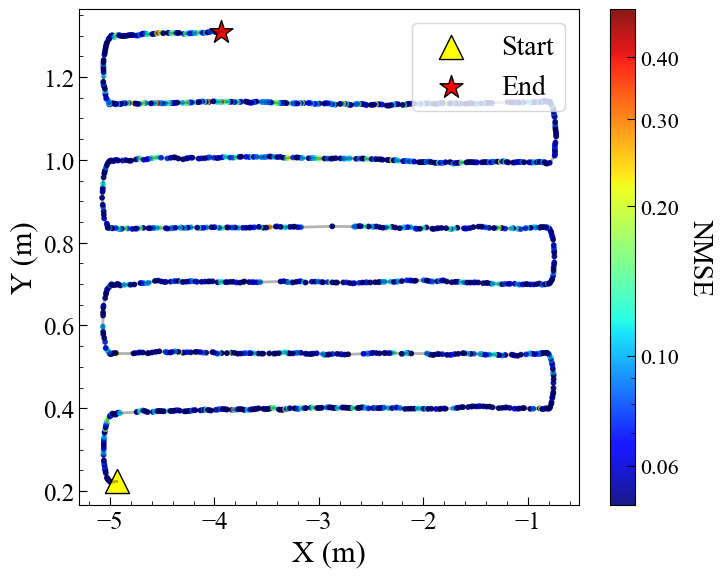

[Info] Loading dichasus-0158, Past Length: 4
✅ Saved: ./results/DICHASUS-015x/trace_heatmap_len4.pdf/jpg


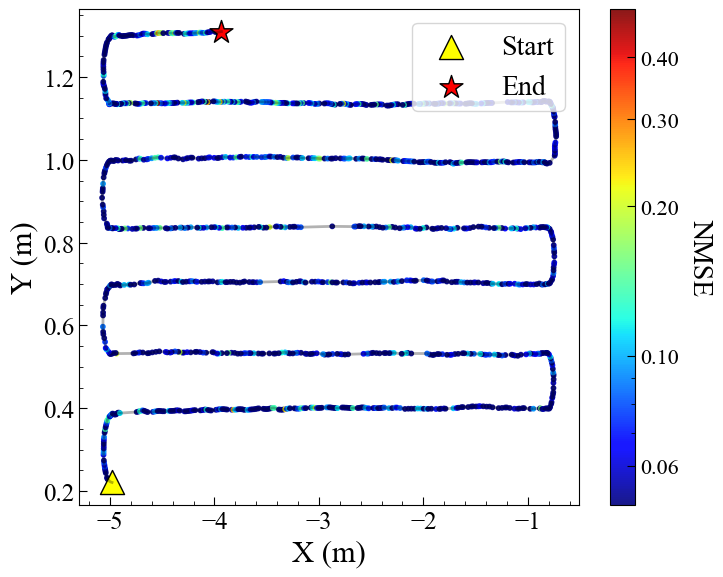

[Info] Loading dichasus-0158, Past Length: 16
✅ Saved: ./results/DICHASUS-015x/trace_heatmap_len16.pdf/jpg


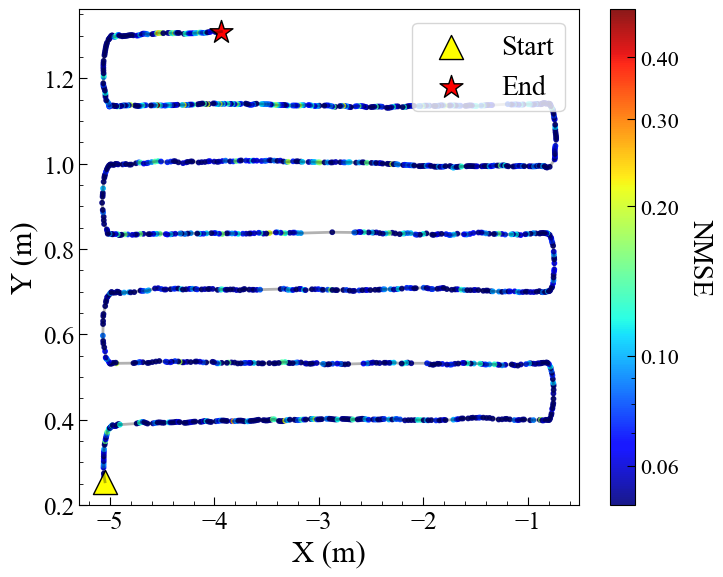

In [61]:
def plot_trajectory(loc, metric, metric_name,
                    fig_name: str = 'trace_heatmap',
                    is_save=None, vmin=None, vmax=None, use_log=True):
    """
    绘制轨迹图，颜色表示指标高低
    """
    import numpy as np
    import matplotlib.pyplot as plt
    from matplotlib import colors, ticker

    # 提取坐标
    x = loc[:, 0]
    y = loc[:, 1]

    fig, ax = plt.subplots(figsize=(7.5, 6))

    # 1. 设置颜色映射规范
    if use_log:
        if metric.min() <= 0:
            print("[Warning] 数据包含 <= 0 的值，对数图会自动过滤这些点或设为极小值。")
            metric = np.maximum(metric, 1e-8)

        if vmin is None:
            vmin = metric.min()
        if vmax is None:
            vmax = metric.max()

        norm = colors.LogNorm(vmin=vmin, vmax=vmax)
    else:
        norm = plt.Normalize(vmin=vmin, vmax=vmax)

    # 2. 轨迹线
    ax.plot(x, y, color='black', alpha=0.3, linewidth=2)

    # 3. 散点
    cmap = 'jet'
    sc = ax.scatter(x, y, c=metric, cmap=cmap, norm=norm, s=10, alpha=0.9)

    # 4. 起点和终点
    ax.scatter(x[0], y[0], c='yellow', s=300, marker='^', edgecolors='k', label='Start')
    ax.scatter(x[-1], y[-1], c='red', s=300, marker='*', edgecolors='k', label='End')

    # =========================
    # 5. 设置 colorbar
    # =========================
    if use_log:
        # 自定义 colorbar 刻度
        cbar_ticks = [0.06, 0.1, 0.2, 0.3, 0.4]
        cbar = plt.colorbar(sc, ax=ax, ticks=cbar_ticks)

        # 对数形式标签显示
        cbar.ax.yaxis.set_major_formatter(ticker.FormatStrFormatter('%.2f'))
    else:
        cbar = plt.colorbar(sc, ax=ax)

    # colorbar 标签字体大小
    cbar.set_label(f"{metric_name.upper()}", rotation=270, labelpad=25, fontsize=20)

    # colorbar 刻度字体大小
    cbar.ax.tick_params(labelsize=16)

    # =========================
    # 6. 设置坐标轴
    # =========================
    ax.set_xlabel("X (m)", fontsize=22)
    ax.set_ylabel("Y (m)", fontsize=22)

    # x、y 轴刻度位置
    ax.set_xticks(np.arange(-5.0, -0.5, 1.0))   # 例如: -5, -4, -3, -2, -1
    ax.set_yticks(np.arange(0.2, 1.4, 0.2))     # 例如: 0.2, 0.4, ..., 1.2

    # x、y 轴刻度字体大小
    ax.tick_params(axis='both', which='major', labelsize=18)

    # 如果想加密次刻度
    # ax.xaxis.set_minor_locator(ticker.MultipleLocator(0.2))
    # ax.yaxis.set_minor_locator(ticker.MultipleLocator(0.05))
    # ax.tick_params(axis='both', which='minor', length=4)

    ax.legend(loc='upper right', fontsize=20)

    plt.tight_layout()
    if is_save:
        save_plot(f"{fig_name}")
    plt.show()
    plt.close()

input_config = '8antx8car'
train_data_config = 'data36k-nei32'
model_name_list = ['AFCoupler']
trace_filename_prefix = 'trace_smooth_metrics'
trace_part_name = 'dichasus-0158'
past_len_list = [0, 1, 4, 16]
fig_name = 'trace_heatmap'
schemes = itertools.product(model_name_list, past_len_list)
for (model_name, past_len) in schemes:
    h5_filename = f"{trace_filename_prefix}_{trace_part_name}_pastlen{past_len}.h5"
    loc, metric, past_len, part_name = load_and_align_data(input_config, model_name, h5_filename, 'nmse_list_ar',
                                                           train_data_config=train_data_config)
    plot_trajectory(loc, metric, 'NMSE', fig_name=f"{fig_name}_len{past_len}",
                    is_save=True, vmin=0.05, vmax=0.5)


正在对比 Model: AFCoupler 的不同 History Length...
[Info] Loading dichasus-0158, Past Length: 0
[Info] Loading dichasus-0158, Past Length: 1
[Info] Loading dichasus-0158, Past Length: 4
[Info] Loading dichasus-0158, Past Length: 16
[Info] Loading dichasus-0158, Past Length: 16
[Info] 已添加 Ideal 参考线 (Source: past_len=16)
✅ Saved: ./results/DICHASUS-015x/NMSE_trace_compare_pastlens_conference.pdf/jpg


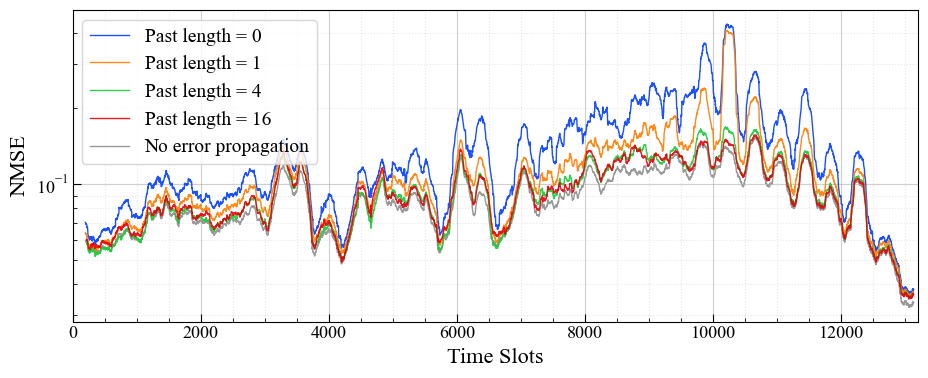

In [53]:
def plot_nmse_lines_comparison(input_config, model_name, train_data_config,
                               trace_filename_prefix, trace_part_name,
                               past_len_list,
                               fig_name='NMSE_trace_compare_pastlens',
                               is_save=None,
                               smooth_window=None,
                               downsample_step=None, # [新增] 降采样步长
                               ideal_source_past_len=None):
    """
    绘制不同 past_len 下 NMSE 随时间变化的折线对比图 (对数尺度 Y 轴)

    Args:
        smooth_window: (int) 滑动平均窗口大小。如果为None则不平滑。
        downsample_step: (int) 降采样步长。例如设为10，则每10个点取1个点绘制。
        ideal_source_past_len: (int) 如果不为None，则从该past_len对应的文件中读取 nmse_list_ideal 并绘制灰色虚线
    """

    # 初始化画布
    fig, ax = plt.subplots(figsize=(9, 4))

    print(f"正在对比 Model: {model_name} 的不同 History Length...")

    # 使用 seaborn 的调色板
    import seaborn as sns # 用于获取好看的颜色
    palette = sns.color_palette("bright", len(past_len_list))

    # 定义一个内部数据处理函数，避免代码重复
    def process_data(metric_data, start_idx):
        # 1. 生成原始 X 轴
        x = np.arange(start_idx, start_idx + len(metric_data))
        y = metric_data

        # 2. 平滑处理 (Smoothing)
        if smooth_window and smooth_window > 1:
            kernel = np.ones(smooth_window) / smooth_window
            y = np.convolve(y, kernel, mode='valid')
            # valid 模式下，数据长度减少 smooth_window - 1
            x = x[smooth_window-1:]

        # 3. 降采样处理 (Downsampling)
        if downsample_step and downsample_step > 1:
            x = x[::downsample_step]
            y = y[::downsample_step]

        return x, y

    # --- 1. 绘制 AR (Auto-Regressive) 曲线 ---
    for i, past_len in enumerate(past_len_list):
        h5_filename = f"{trace_filename_prefix}_{trace_part_name}_pastlen{past_len}.h5"

        # 加载 AR 数据 (假设 load_and_align_data 已经在上下文定义好)
        try:
            _, metric, loaded_past_len, _ = load_and_align_data(
                input_config, model_name, h5_filename, 'nmse_list_ar', train_data_config=train_data_config
            )
        except Exception as e:
            print(f"[Warning] 跳过 {past_len}: {e}")
            continue

        # 处理数据
        x_axis, plot_data = process_data(metric, loaded_past_len)

        # 绘制
        ax.plot(x_axis, plot_data,
                label=f'Past length = {past_len}',
                color=palette[i],
                linewidth=1,
                alpha=0.9)

    # --- 2. 绘制 Ideal (No Error Propagation) 参考线 ---
    if ideal_source_past_len is not None:
        h5_filename_ideal = f"{trace_filename_prefix}_{trace_part_name}_pastlen{ideal_source_past_len}.h5"
        try:
            _, metric_ideal, loaded_past_len_ideal, _ = load_and_align_data(
                input_config, model_name, h5_filename_ideal, 'nmse_list_ideal', train_data_config=train_data_config
            )

            # 处理数据 (同样应用平滑和降采样，保持视觉一致性)
            x_axis_ideal, plot_data_ideal = process_data(metric_ideal, loaded_past_len_ideal)

            # 绘制灰色虚线
            ax.plot(x_axis_ideal, plot_data_ideal,
                    label='No error propagation',
                    color='gray',
                    linestyle='-',
                    linewidth=1,
                    alpha=0.8,
                    zorder=0)

            print(f"[Info] 已添加 Ideal 参考线 (Source: past_len={ideal_source_past_len})")
        except Exception as e:
            print(f"[Warning] 无法加载 Ideal 参考线: {e}")

    # --- 3. 设置坐标轴 ---
    plt.xlim(0, 13200)
    ax.set_yscale('log')
    ax.yaxis.set_major_locator(ticker.LogLocator(base=10.0, numticks=10))

    # --- 4. 装饰 ---
    ax.set_xlabel("Time Slots", fontsize=16)
    ax.set_ylabel("NMSE", fontsize=16)

    ax.grid(True, which="major", ls="-", alpha=0.6)
    ax.grid(True, which="minor", ls=":", alpha=0.3)

    ax.legend(loc='upper left', frameon=True, fontsize=14)

    plt.tight_layout()
    if is_save:
        save_plot(f"{fig_name}")
    plt.show()

# ==========================================
# 执行示例
# ==========================================
input_config = '8antx8car'
train_data_config = 'data36k-nei32'
model_name = 'AFCoupler'
trace_filename_prefix = 'trace_smooth_metrics'
trace_part_name = 'dichasus-0158'
past_len_list = [0, 1, 4, 16]

# 调用方式：只降采样，不平滑
plot_nmse_lines_comparison(
    input_config, model_name, train_data_config,
    trace_filename_prefix, trace_part_name,
    past_len_list,
    fig_name='NMSE_trace_compare_pastlens_conference',
    is_save=True,
    smooth_window=200,    # 关闭平滑
    # downsample_step=10,    # 每10个点取1个
    ideal_source_past_len=16,
)

正在对比 Model: AFCoupler 的不同 History Length...
[Info] Loading dichasus-0158, Past Length: 0
[Info] 已添加 LMMSE 对比曲线
[Info] Loading dichasus-0158, Past Length: 0
[Info] Loading dichasus-0158, Past Length: 1
[Info] Loading dichasus-0158, Past Length: 4
[Info] Loading dichasus-0158, Past Length: 16
[Info] Loading dichasus-0158, Past Length: 16
[Info] 已添加 Ideal 参考线 (Source: past_len=16)
✅ Saved: ./results/DICHASUS-015x/NMSE_trace_compare_pastlens_v2.pdf/jpg


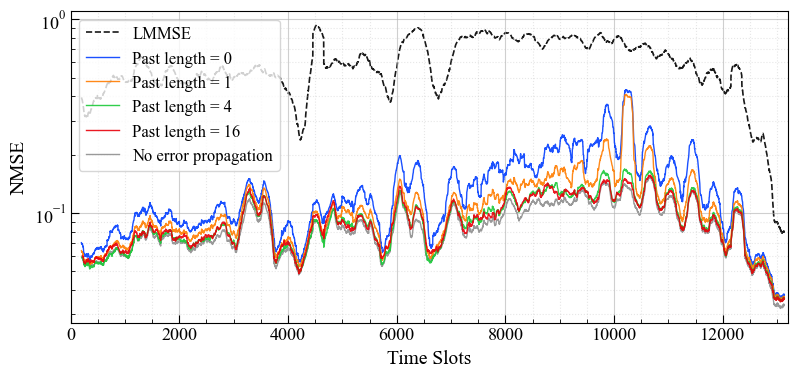

In [57]:
def plot_nmse_lines_comparison(input_config, model_name, train_data_config,
                               trace_filename_prefix, trace_part_name,
                               past_len_list,
                               fig_name='NMSE_trace_compare_pastlens',
                               is_save=None,
                               smooth_window=None,
                               downsample_step=None, # [新增] 降采样步长
                               ideal_source_past_len=None,
                               include_lmmse=False):
    """
    绘制不同 past_len 下 NMSE 随时间变化的折线对比图 (对数尺度 Y 轴)

    Args:
        smooth_window: (int) 滑动平均窗口大小。如果为None则不平滑。
        downsample_step: (int) 降采样步长。例如设为10，则每10个点取1个点绘制。
        ideal_source_past_len: (int) 如果不为None，则从该past_len对应的文件中读取 nmse_list_ideal 并绘制灰色虚线
        include_lmmse: (bool) 是否额外加载并绘制 LMMSE 的测试结果进行比较
    """

    # 初始化画布
    fig, ax = plt.subplots(figsize=(8.2, 4))

    print(f"正在对比 Model: {model_name} 的不同 History Length...")

    # 使用 seaborn 的调色板
    import seaborn as sns # 用于获取好看的颜色
    palette = sns.color_palette("bright", len(past_len_list))

    # 定义一个内部数据处理函数，避免代码重复
    def process_data(metric_data, start_idx):
        # 1. 生成原始 X 轴
        x = np.arange(start_idx, start_idx + len(metric_data))
        y = metric_data

        # 2. 平滑处理 (Smoothing)
        if smooth_window and smooth_window > 1:
            kernel = np.ones(smooth_window) / smooth_window
            y = np.convolve(y, kernel, mode='valid')
            x = x[smooth_window-1:]

        # 3. 降采样处理 (Downsampling)
        if downsample_step and downsample_step > 1:
            x = x[::downsample_step]
            y = y[::downsample_step]

        return x, y

    # --- 2. 绘制 LMMSE 参考线 ---
    if include_lmmse:
        h5_filename_lmmse = f"{trace_filename_prefix}_{trace_part_name}_pastlen0.h5"
        try:
            _, metric_lmmse, loaded_past_len_lmmse, _ = load_and_align_data(
                input_config, 'LMMSE', h5_filename_lmmse, 'nmse_list_ar', train_data_config=train_data_config
            )

            x_axis_lmmse, plot_data_lmmse = process_data(metric_lmmse, loaded_past_len_lmmse)

            ax.plot(x_axis_lmmse, plot_data_lmmse,
                    label='LMMSE',
                    color='black',
                    linestyle='--',
                    linewidth=1.2,
                    alpha=0.9,
                    zorder=1)

            print("[Info] 已添加 LMMSE 对比曲线")
        except Exception as e:
            print(f"[Warning] 无法加载 LMMSE 对比曲线: {e}")

    # --- 1. 绘制 AR (Auto-Regressive) 曲线 ---
    for i, past_len in enumerate(past_len_list):
        h5_filename = f"{trace_filename_prefix}_{trace_part_name}_pastlen{past_len}.h5"

        try:
            _, metric, loaded_past_len, _ = load_and_align_data(
                input_config, model_name, h5_filename, 'nmse_list_ar', train_data_config=train_data_config
            )
        except Exception as e:
            print(f"[Warning] 跳过 {past_len}: {e}")
            continue

        x_axis, plot_data = process_data(metric, loaded_past_len)

        ax.plot(x_axis, plot_data,
                label=f'Past length = {past_len}',
                color=palette[i],
                linewidth=1,
                alpha=0.9)

    # --- 3. 绘制 Ideal (No Error Propagation) 参考线 ---
    if ideal_source_past_len is not None:
        h5_filename_ideal = f"{trace_filename_prefix}_{trace_part_name}_pastlen{ideal_source_past_len}.h5"
        try:
            _, metric_ideal, loaded_past_len_ideal, _ = load_and_align_data(
                input_config, model_name, h5_filename_ideal, 'nmse_list_ideal', train_data_config=train_data_config
            )

            x_axis_ideal, plot_data_ideal = process_data(metric_ideal, loaded_past_len_ideal)

            ax.plot(x_axis_ideal, plot_data_ideal,
                    label='No error propagation',
                    color='gray',
                    linestyle='-',
                    linewidth=1,
                    alpha=0.8,
                    zorder=0)

            print(f"[Info] 已添加 Ideal 参考线 (Source: past_len={ideal_source_past_len})")
        except Exception as e:
            print(f"[Warning] 无法加载 Ideal 参考线: {e}")

    # --- 4. 设置坐标轴 ---
    plt.xlim(0, 13200)
    ax.set_yscale('log')
    ax.yaxis.set_major_locator(ticker.LogLocator(base=10.0, numticks=10))

    # --- 5. 装饰 ---
    ax.tick_params(axis='both', which='major', labelsize=13)  # x、y 轴刻度字体大小
    ax.set_xlabel("Time Slots", fontsize=14)
    ax.set_ylabel("NMSE", fontsize=14)

    ax.grid(True, which="major", ls="-", alpha=0.6)
    ax.grid(True, which="minor", ls=":", alpha=0.3)

    ax.legend(loc='upper left', frameon=True, fontsize=12)

    plt.tight_layout()
    if is_save:
        save_plot(f"{fig_name}")
    plt.show()

# ==========================================
# 执行示例
# ==========================================
input_config = '8antx8car'
train_data_config = 'data36k-nei32'
model_name = 'AFCoupler'
trace_filename_prefix = 'trace_smooth_metrics'
trace_part_name = 'dichasus-0158'
past_len_list = [0, 1, 4, 16]

plot_nmse_lines_comparison(
    input_config, model_name, train_data_config,
    trace_filename_prefix, trace_part_name,
    past_len_list,
    fig_name='NMSE_trace_compare_pastlens_v2',
    is_save=True,
    smooth_window=200,
    ideal_source_past_len=16,
    include_lmmse=True,
)
